<a href="https://colab.research.google.com/github/sarthak-chougale/mis-report-agent/blob/main/mis_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install groq

In [4]:
from google.colab import userdata
from groq import Groq

client = Groq(api_key=userdata.get("GROQ_API_KEY"))
MODEL = "openai/gpt-oss-20b"

r = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "Ek line madhe Marathi madhe namaskar bol"}],
)
print(r.choices[0].message.content)

नमस्कार, सर्वांना हार्दिक स्वागत!


In [5]:
import pandas as pd, numpy as np

np.random.seed(42)
n = 600
dates = pd.date_range("2026-01-01", "2026-10-31")
prices = {"Bread": 30, "Cake": 450, "Cookies": 120,
          "Pastry": 60, "Puff": 25, "Biscuit": 40}
regions = ["Kolhapur", "Pune", "Sangli", "Satara"]

df = pd.DataFrame({
    "date": np.random.choice(dates, n),
    "product": np.random.choice(list(prices), n),
    "region": np.random.choice(regions, n),
    "qty": np.random.randint(1, 30, n),
})
df["price"] = df["product"].map(prices)
df["revenue"] = df["qty"] * df["price"]
df = df.sort_values("date")
df.to_csv("sales.csv", index=False)

df.head()

,date,product,region,qty,price,revenue
545,2026-01-01,Pastry,Satara,12,60,720
369,2026-01-01,Cookies,Pune,18,120,2160
570,2026-01-01,Pastry,Pune,19,60,1140
48,2026-01-02,Bread,Kolhapur,12,30,360
217,2026-01-02,Biscuit,Pune,12,40,480


In [7]:
import matplotlib.pyplot as plt

def load():
    return pd.read_csv("sales.csv", parse_dates=["date"])

def overview():
    d = load()
    return {
        "rows": len(d),
        "columns": list(d.columns),
        "date_from": str(d["date"].min().date()),
        "date_to": str(d["date"].max().date()),
        "total_revenue": int(d["revenue"].sum()),
    }

def group_sum(group_col, value_col="revenue", top_n=5):
    d = load()
    s = (d.groupby(group_col)[value_col].sum()
           .sort_values(ascending=False).head(top_n))
    return {str(k): int(v) for k, v in s.items()}

def monthly_trend(value_col="revenue"):
    d = load()
    s = d.groupby(d["date"].dt.to_period("M"))[value_col].sum()
    return {str(k): int(v) for k, v in s.items()}

def make_chart(group_col, value_col="revenue"):
    data = group_sum(group_col, value_col, top_n=10)
    plt.figure(figsize=(7, 4))
    plt.bar(list(data.keys()), list(data.values()))
    plt.title(f"{value_col} by {group_col}")
    plt.tight_layout()
    plt.show()
    return {"chart_shown": f"{value_col} by {group_col}"}

{'rows': 600, 'columns': ['date', 'product', 'region', 'qty', 'price', 'revenue'], 'date_from': '2026-01-01', 'date_to': '2026-10-31', 'total_revenue': 1034765}
{'Cake': 624150, 'Cookies': 179760, 'Pastry': 80160, 'Biscuit': 65040, 'Bread': 47280}
{'Kolhapur': 288585, 'Sangli': 275950, 'Pune': 270775, 'Satara': 199455}
{'2026-01': 63760, '2026-02': 112995, '2026-03': 66235, '2026-04': 77450, '2026-05': 129715, '2026-06': 140535, '2026-07': 106885, '2026-08': 143220, '2026-09': 107815, '2026-10': 86155}


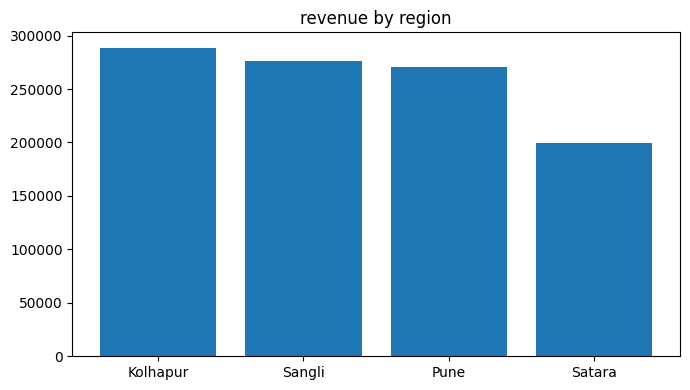

{'chart_shown': 'revenue by region'}

In [8]:
print(overview())
print(group_sum("product"))
print(group_sum("region"))
print(monthly_trend())
make_chart("region")

In [9]:
import json

stats = {
    "overview": overview(),
    "by_product": group_sum("product", top_n=6),
    "by_region": group_sum("region", top_n=4),
    "monthly": monthly_trend(),
}
print(json.dumps(stats, indent=2))

{
  "overview": {
    "rows": 600,
    "columns": [
      "date",
      "product",
      "region",
      "qty",
      "price",
      "revenue"
    ],
    "date_from": "2026-01-01",
    "date_to": "2026-10-31",
    "total_revenue": 1034765
  },
  "by_product": {
    "Cake": 624150,
    "Cookies": 179760,
    "Pastry": 80160,
    "Biscuit": 65040,
    "Bread": 47280,
    "Puff": 38375
  },
  "by_region": {
    "Kolhapur": 288585,
    "Sangli": 275950,
    "Pune": 270775,
    "Satara": 199455
  },
  "monthly": {
    "2026-01": 63760,
    "2026-02": 112995,
    "2026-03": 66235,
    "2026-04": 77450,
    "2026-05": 129715,
    "2026-06": 140535,
    "2026-07": 106885,
    "2026-08": 143220,
    "2026-09": 107815,
    "2026-10": 86155
  }
}


In [10]:
prompt = f"""You are a data analyst. Using ONLY these numbers, write:
1) 5 short bullet insights
2) 2 practical recommendations
Do not invent any number. Simple English.

{json.dumps(stats, indent=2)}"""

r = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": prompt}],
    temperature=0.3,
)
summary = r.choices[0].message.content
print(summary)

**Insights**

- Total revenue for the period is **1,034,765**.
- **Cake** sales are the biggest share – **624,150** (about 60 % of total revenue).
- The **Kolhapur** region brings in the most money – **288,585** (roughly 28 % of total).
- Monthly revenue peaks in **June** (**140,535**) and is lowest in **January** (**63,760**).
- The lower‑margin items **Pastry** (**80,160**) and **Biscuit** (**65,040**) contribute the least to revenue.

**Recommendations**

- Put more marketing and inventory focus on **Cake**, since it generates the majority of revenue.
- Run targeted promotions in **Kolhapur** to keep its high sales momentum and possibly extend the strategy to similar high‑performing regions.



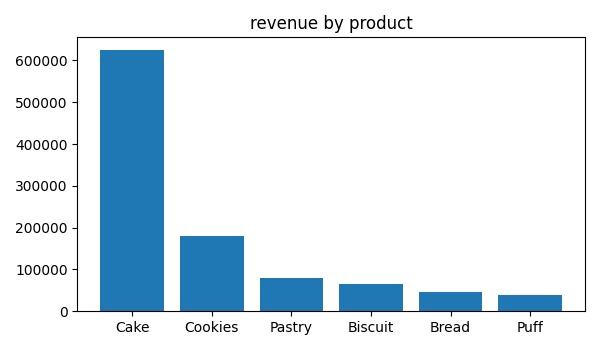
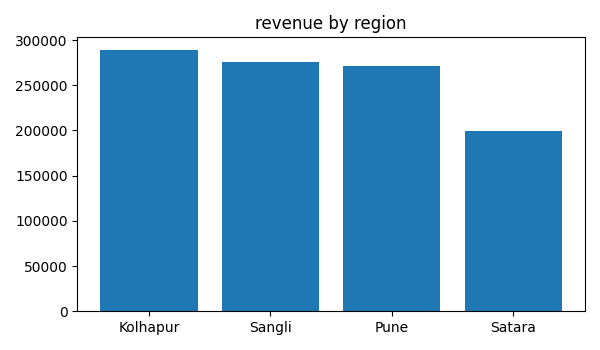

In [11]:
import io, base64
from IPython.display import HTML, display

def chart_b64(group_col, value_col="revenue"):
    data = group_sum(group_col, value_col, top_n=10)
    plt.figure(figsize=(6, 3.5))
    plt.bar(list(data.keys()), list(data.values()))
    plt.title(f"{value_col} by {group_col}")
    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format="png")
    plt.close()
    return base64.b64encode(buf.getvalue()).decode()

img1 = chart_b64("product")
img2 = chart_b64("region")
o = stats["overview"]

html = f"""
<div style="font-family:Arial;max-width:850px">
<h1>Sales MIS Report</h1>
<p>Period: {o['date_from']} to {o['date_to']}<br>
<b>Total revenue: ₹{o['total_revenue']:,}</b></p>
<img src="data:image/png;base64,{img1}" width="400">
<img src="data:image/png;base64,{img2}" width="400">
<h2>AI Summary</h2>
<pre style="white-space:pre-wrap;font-family:Arial">{summary}</pre>
</div>
"""

display(HTML(html))

with open("report.html", "w", encoding="utf-8") as f:
    f.write(html)

In [12]:
from google.colab import files
files.download("report.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### GitHub वर सेव्ह कसे करावे:

खालील चित्रात दाखवल्याप्रमाणे, वरच्या डाव्या कोपऱ्यात असलेल्या **File** वर क्लिक करा, आणि नंतर **Save a copy in GitHub** हा पर्याय निवडा:

![Colab Save to GitHub Menu](https://raw.githubusercontent.com/googlecolab/colabtools/main/google/colab/resources/colab-github-save.png)

In [13]:
import json

FUNCS = {
    "overview": overview,
    "group_sum": group_sum,
    "monthly_trend": monthly_trend,
    "make_chart": make_chart,
}

TOOLS = [
    {"type": "function", "function": {
        "name": "overview",
        "description": "Get dataset summary: rows, columns, date range, total revenue.",
        "parameters": {"type": "object", "properties": {}}}},
    {"type": "function", "function": {
        "name": "group_sum",
        "description": "Sum a value column grouped by a column, e.g. revenue by product or region.",
        "parameters": {"type": "object", "properties": {
            "group_col": {"type": "string", "enum": ["product", "region"]},
            "value_col": {"type": "string", "enum": ["revenue", "qty"]},
            "top_n": {"type": "integer"}},
            "required": ["group_col"]}}},
    {"type": "function", "function": {
        "name": "monthly_trend",
        "description": "Monthly totals of revenue or qty.",
        "parameters": {"type": "object", "properties": {
            "value_col": {"type": "string", "enum": ["revenue", "qty"]}}}}},
    {"type": "function", "function": {
        "name": "make_chart",
        "description": "Show a bar chart for revenue or qty grouped by product or region.",
        "parameters": {"type": "object", "properties": {
            "group_col": {"type": "string", "enum": ["product", "region"]},
            "value_col": {"type": "string", "enum": ["revenue", "qty"]}},
            "required": ["group_col"]}}},
]

print("Tools ready:", list(FUNCS.keys()))

Tools ready: ['overview', 'group_sum', 'monthly_trend', 'make_chart']


In [14]:
SYSTEM = """You are a sales data analyst assistant for a bakery business.
Always use tools to get numbers. Never guess or invent numbers.
If asked for a chart, call make_chart.
Reply in simple Romanized Marathi, short, with rupee amounts."""

messages = [{"role": "system", "content": SYSTEM}]

def ask(question):
    messages.append({"role": "user", "content": question})

    for step in range(8):          # safety: max 8 steps
        resp = client.chat.completions.create(
            model=MODEL, messages=messages,
            tools=TOOLS, tool_choice="auto")
        msg = resp.choices[0].message

        # LLM la tool nako, uttar tayar ahe
        if not msg.tool_calls:
            messages.append({"role": "assistant", "content": msg.content})
            return msg.content

        # LLM la tool pahije
        messages.append({
            "role": "assistant", "content": msg.content,
            "tool_calls": [{"id": t.id, "type": "function",
                            "function": {"name": t.function.name,
                                         "arguments": t.function.arguments}}
                           for t in msg.tool_calls]})

        for t in msg.tool_calls:
            args = json.loads(t.function.arguments or "{}")
            print(f"  [tool] {t.function.name} {args}")
            try:
                result = FUNCS[t.function.name](**args)
            except Exception as e:
                result = {"error": str(e)}
            messages.append({"role": "tool", "tool_call_id": t.id,
                             "content": json.dumps(result)})

    return "Khup steps zale, parat vichar."

print("Agent ready")

Agent ready


In [15]:
print(ask("Total sales kiti zali?"))

  [tool] overview {}
Total sales ₹10,34,765.


In [ ]:
print("MIS Agent ready. 'exit' lihun baher ye.\n")

while True:
    q = input("Tu: ")
    if q.strip().lower() == "exit":
        print("Bye!")
        break
    print("\nAgent:", ask(q), "\n")

MIS Agent ready. 'exit' lihun baher ye.

Tu: hya month madhye total kiti profit zala ??

Agent: माझ्याकडे फक्त revenue (₹10,34,765) ची माहिती आहे. profit‑ची माहिती dataset मध्ये उपलब्ध नाही. 

Tu: lonkacha konte product favorite ahe ?
  [tool] group_sum {'group_col': 'product', 'top_n': 1, 'value_col': 'revenue'}

Agent: सर्वाधिक आवडलेलं उत्पादन “Cake” आहे. ते सर्वाधिक ₹6,24,150 revenue बनवते. 

